**Introducción a la Ciencia de Datos 2026**  
Posgrado en Ciencias de la Computación - CICESE  
Erick Gabriel Santiago Suenaga

## Práctica 3: Tarea de clasificación
---

## Contexto y procedencia del dataset

El conjunto describe a estudiantes de licenciatura del Instituto Politécnico de Portalegre, en Portugal, que ingresaron entre los ciclos 2008/09 y 2018/19. Cada fila es un estudiante, con datos de su ingreso (carrera, forma de admisión, notas de ingreso), de su perfil personal y familiar (edad, estado civil, estudios y ocupación de los padres), de su situación económica (becas, deudas, colegiatura al corriente), de su desempeño en el primer y el segundo semestre (unidades inscritas, aprobadas y su nota media) y de tres indicadores económicos del país (desempleo, inflación y PIB). La variable objetivo, Target, es la situación del estudiante al final de la duración normal de su carrera: **graduado** (*Graduate*), **desertor** (*Dropout*) o **todavía inscrito** (*Enrolled*).

Se quiere saber qué situación tendrá cada estudiante (variable target) justo al cierre del primer semestre, ya que saberlo a tiempo permite ofrecer apoyo a quienes están en riesgo. Para esto se comparan cinco clasificadores vistos en clase los cuales son árbol de decisión, Naive Bayes, kNN, SVM y regresión logística, cada uno llevado a su mejor versión con una búsqueda de hiperparámetros con validación cruzada estratificada. El criterio principal es el **F1 macro**, que promedia el F1 de las tres clases sin favorecer a la más numerosa. No se usan ensambles ni redes neuronales. Se hizo una partición de los datos del dataset original, unos para entrenar y otros para prueba, al final se entrena el mejor clasificador con todo el entrenamiento y se predicen los 885 estudiantes de prueba.

## Descripción del problema y de los datos

| Elemento | Detalle |
|---|---|
| **Fuente** | UCI Machine Learning Repository, *Predict Students' Dropout and Academic Success* (conjunto 697), de Realinho, Machado, Baptista y Martins |
| **Procedencia** | Estudiantes de licenciatura del Instituto Politécnico de Portalegre, Portugal, que ingresaron entre los ciclos 2008/09 y 2018/19 |
| **Unidad de observación** | Un estudiante |
| **Variable objetivo** | `Target`: situación del estudiante al final de la duración normal de la carrera (*Dropout*, *Enrolled* o *Graduate*) |
| **Archivos** | `desercion-entrenamiento.csv` (3,539 estudiantes, con `Target`) y `desercion-prueba.csv` (885 estudiantes, sin `Target`) |
| **Licencia** | Creative Commons Attribution 4.0 (CC BY 4.0), según la ficha del dataset en UCI |
| **Referencia** | https://doi.org/10.24432/C5MC89 · Realinho, V., Machado, J., Baptista, L., & Martins, M. V. (2022). Predicting student dropout and academic success. *Data, 7*(11), 146. https://doi.org/10.3390/data7110146 |

---

## Preparación

Se declaran las versiones de las librerías, en este caso se instala una versión específica para scikit learn, se fija la semilla y se definen los colores de las gráficas. Las rutas son relativas: los dos archivos CSV deben estar en la misma carpeta que este notebook.

In [1]:
!pip install scikit-learn==1.7.0

In [2]:
import sys, time, random, platform, warnings
import numpy as np
import pandas as pd
import scipy
import sklearn
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from cycler import cycler
from scipy.stats import loguniform, randint, uniform

from sklearn.model_selection import (StratifiedKFold, RepeatedStratifiedKFold, ParameterSampler,
                                     cross_validate, cross_val_predict)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import (OneHotEncoder, OrdinalEncoder, StandardScaler, MinMaxScaler,
                                   KBinsDiscretizer, PowerTransformer, FunctionTransformer)
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB, CategoricalNB, MultinomialNB, ComplementNB, BernoulliNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix
from sklearn.exceptions import ConvergenceWarning

# Una configuración que no converge simplemente obtiene un F1 bajo y pierde la comparación;
# no hace falta llenar la salida de avisos. Tampoco los de bins repetidos al discretizar.
warnings.filterwarnings("ignore", category=ConvergenceWarning)
warnings.filterwarnings("ignore", category=UserWarning, module="sklearn.preprocessing._discretization")

SEMILLA = 42
random.seed(SEMILLA)
np.random.seed(SEMILLA)
pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 30)

print("Python      ", platform.python_version())
for nombre, modulo in [("numpy", np), ("pandas", pd), ("scipy", scipy), ("scikit-learn", sklearn),
                       ("matplotlib", matplotlib), ("seaborn", sns)]:
    print(f"{nombre:<12}", modulo.__version__)

Python       3.13.18
numpy        2.4.6
pandas       2.2.3
scipy        1.16.3
scikit-learn 1.7.0
matplotlib   3.10.0
seaborn      0.13.2


In [3]:
AZUL_OSCURO = "#112057"
AZUL = "#7697CD"
NARANJA = "#E76A28"
GRIS = "#5B6584"

plt.rcParams.update({
    "figure.dpi": 100,
    "axes.titlecolor": AZUL_OSCURO,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.labelcolor": AZUL_OSCURO,
    "axes.edgecolor": "#C9CFDF",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#E3E6EF",
    "xtick.color": GRIS,
    "ytick.color": GRIS,
    "legend.frameon": False,
    "axes.prop_cycle": cycler(color=[AZUL_OSCURO, NARANJA, AZUL, GRIS]),
})

In [4]:
RUTA_ENTRENAMIENTO = "desercion-entrenamiento.csv"
RUTA_PRUEBA = "desercion-prueba.csv"
RUTA_SALIDA = "predicciones.csv"

tr = pd.read_csv(RUTA_ENTRENAMIENTO)
te = pd.read_csv(RUTA_PRUEBA)
print("Entrenamiento:", tr.shape, "| Prueba:", te.shape)
tr.head(3)

Entrenamiento: (3539, 38) | Prueba: (885, 31)


,id,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,Mother's occupation,Father's occupation,Admission grade,Displaced,...,Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,1,1,2,9500,1,1,140.0,1,38,37,5,6,124.3,1,...,7,9,7,13.312500,0,0,8,8,8,15.637500,0,13.9,-0.3,0.79,Graduate
1,2,1,17,1,8014,0,1,125.0,1,37,37,5,6,122.2,1,...,6,6,6,12.166667,0,0,6,7,6,11.666667,0,10.8,1.4,1.74,Graduate
2,3,1,39,1,9991,0,1,130.0,1,1,1,9,7,152.1,0,...,5,13,2,11.000000,0,0,5,12,1,12.000000,0,11.1,0.6,2.02,Dropout


### Qué se sabe y cuándo

El nombre de las columnas sigue la ficha de UCI. Los atributos se dividen por su naturaleza, porque de eso depende el preprocesamiento:

| Grupo | Atributos | Ejemplos |
|---|---|---|
| **Nominales codificados como enteros** (9) | El número es un código, no una cantidad: el 3 no es «mayor» que el 1 | `Marital status`, `Application mode`, `Course`, `Previous qualification`, `Nacionality`, ocupación y estudios de la madre y del padre |
| **Binarios 0/1** (8) | Ya son indicadores | `Debtor`, `Tuition fees up to date`, `Gender`, `Scholarship holder`, `Displaced`, `International`, `Educational special needs`, `Daytime/evening attendance` |
| **Numéricos** (13) | Cantidades, notas, edades, un orden de preferencia y tres indicadores macroeconómicos | `Admission grade`, `Age at enrollment`, `Application order`, las seis variables de unidades curriculares del primer semestre, `Unemployment rate`, `Inflation rate`, `GDP` |
| **Segundo semestre** (6) | Mismas seis variables de unidades curriculares, pero del segundo semestre | `Curricular units 2nd sem (approved)`, etc. |

**Información disponible al decidir.** El modelo debe decidir al cierre del primer semestre, así que solo puede usar los 30 atributos de los tres primeros grupos. Los seis atributos del segundo semestre existen únicamente en el archivo de entrenamiento y se dejan fuera del modelo; solo se usan en la sección 9, para estimar cuánto se ganaría con esperar.

In [5]:
NOMINALES = ["Marital status", "Application mode", "Course", "Previous qualification", "Nacionality",
             "Mother's qualification", "Father's qualification", "Mother's occupation", "Father's occupation"]
BINARIOS = ["Daytime/evening attendance", "Displaced", "Educational special needs", "Debtor",
            "Tuition fees up to date", "Gender", "Scholarship holder", "International"]
NUMERICOS = ["Application order", "Previous qualification (grade)", "Admission grade", "Age at enrollment",
             "Curricular units 1st sem (credited)", "Curricular units 1st sem (enrolled)",
             "Curricular units 1st sem (evaluations)", "Curricular units 1st sem (approved)",
             "Curricular units 1st sem (grade)", "Curricular units 1st sem (without evaluations)",
             "Unemployment rate", "Inflation rate", "GDP"]
ATRIBUTOS = NOMINALES + BINARIOS + NUMERICOS                       # los 30 que se conocen al cierre del 1.er semestre
SEGUNDO_SEM = [c for c in tr.columns if "2nd sem" in c]            # solo existen en el entrenamiento

# Comprobaciones: la prueba trae exactamente id + los 30 atributos del primer semestre
assert set(te.columns) == set(ATRIBUTOS) | {"id"}
assert set(tr.columns) == set(ATRIBUTOS) | set(SEGUNDO_SEM) | {"id", "Target"}
assert tr["id"].is_unique and te["id"].is_unique and not (set(tr["id"]) & set(te["id"]))

print(f"Atributos: {len(NOMINALES)} nominales + {len(BINARIOS)} binarios + {len(NUMERICOS)} numéricos = {len(ATRIBUTOS)}")
print(f"Segundo semestre (solo entrenamiento): {len(SEGUNDO_SEM)}")
print("Valores nulos en entrenamiento y prueba:", int(tr.isna().sum().sum()), "y", int(te.isna().sum().sum()))
print("Filas duplicadas (sin id) en entrenamiento:", int(tr.drop(columns="id").duplicated().sum()))

Atributos: 9 nominales + 8 binarios + 13 numéricos = 30
Segundo semestre (solo entrenamiento): 6
Valores nulos en entrenamiento y prueba: 0 y 0
Filas duplicadas (sin id) en entrenamiento: 0


          estudiantes     %
Target                     
Dropout          1137  32.1
Enrolled          635  17.9
Graduate         1767  49.9

Si se predijera siempre «Graduate», el F1 macro sería solo 0.222: las otras dos clases tendrían F1 de 0.


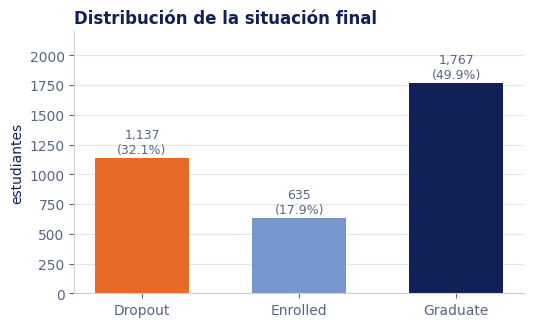

In [6]:
# Las clases se codifican como enteros (alfabéticamente): 0 = Dropout, 1 = Enrolled, 2 = Graduate
CLASES = sorted(tr["Target"].unique())
X = tr[ATRIBUTOS]
y = tr["Target"].map({c: i for i, c in enumerate(CLASES)}).to_numpy()

conteo = tr["Target"].value_counts().reindex(CLASES)
distribucion = pd.DataFrame({"estudiantes": conteo, "%": (conteo / len(tr) * 100).round(1)})
print(distribucion.to_string())
p_g = conteo["Graduate"] / len(tr)
print(f"\nSi se predijera siempre «Graduate», el F1 macro sería solo {2 * p_g / (1 + p_g) / 3:.3f}: las otras dos clases tendrían F1 de 0.")

fig, ax = plt.subplots(figsize=(5.8, 3.4))
ax.bar(CLASES, conteo.values, color=[NARANJA, AZUL, AZUL_OSCURO], width=0.6)
for i, v in enumerate(conteo.values):
    ax.text(i, v + 40, f"{v:,}\n({v / len(tr):.1%})", ha="center", color=GRIS, fontsize=9)
ax.set_ylim(0, 2200)
ax.set_ylabel("estudiantes")
ax.set_title("Distribución de la situación final")
ax.grid(axis="x", visible=False)
plt.show()

In [7]:
cardinalidad = pd.DataFrame({
    "categorías en entrenamiento": [tr[c].nunique() for c in NOMINALES],
    "categorías en prueba": [te[c].nunique() for c in NOMINALES],
    "de prueba, no vistas en entrenamiento": [len(set(te[c]) - set(tr[c])) for c in NOMINALES],
    "categorías con menos de 30 estudiantes": [int((tr[c].value_counts() < 30).sum()) for c in NOMINALES],
}, index=NOMINALES)
cardinalidad

,categorías en entrenamiento,categorías en prueba,"de prueba, no vistas en entrenamiento",categorías con menos de 30 estudiantes
Marital status,6,6,0,3
Application mode,17,15,1,7
Course,17,17,0,1
Previous qualification,17,13,0,10
Nacionality,18,11,3,16
Mother's qualification,26,18,3,17
Father's qualification,32,22,2,23
Mother's occupation,31,23,1,21
Father's occupation,45,29,1,33


**Lectura.** El conjunto de entrenamiento tiene 3,539 estudiantes y está desbalanceado: 49.9 % se gradúa, 32.1 % deserta y 17.9 % sigue inscrito. Por eso la métrica principal es el F1 macro: responder siempre «Graduate» daría casi 50 % de exactitud, pero solo 0.222 de F1 macro. No hay valores nulos ni filas duplicadas, y la prueba trae exactamente los 30 atributos del primer semestre.

Los nominales tienen muchas categorías con muy pocos estudiantes (33 de las 45 ocupaciones del padre tienen menos de 30), y 12 de los 885 estudiantes de prueba traen alguna categoría que no aparece en el entrenamiento (por ejemplo, 3 nacionalidades nuevas). El preprocesamiento debe, entonces, agrupar las categorías raras y tolerar las nuevas.

---

## 1. Protocolo común para los cinco clasificadores

- **Mismos pliegues.** Se construye una sola lista de 5 pliegues estratificados con semilla fija (`PLIEGUES`) y todos los clasificadores se evalúan con ella.
- **Métrica.** F1 macro de validación, y su media y desviación estándar entre los 5 pliegues.
- **Búsqueda aleatoria.** Cada clasificador evalúa **100 configuraciones** muestreadas con `ParameterSampler` y la misma semilla. Se escogió la búsqueda aleatoria porque cada espacio mezcla hiperparámetros discretos, continuos (en escala logarítmica) y condicionales, como `gamma`, que solo existe para algunos kernels. Cada espacio es una lista de diccionarios: primero se elige uno al azar y luego se muestrean sus valores.
- **Todo dentro de un `Pipeline`.** El preprocesamiento se ajusta solo con los datos de entrenamiento de cada pliegue, para que la validación no vea los pliegues de prueba.
- **Categorías raras y no vistas.** Los códigos nominales tienen muchas categorías con muy pocos estudiantes. Con `OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=m)`, las categorías con menos de `m` estudiantes se agrupan en una sola, y las categorías de prueba que no estén en el entrenamiento caen en ese grupo. El umbral `m` es un hiperparámetro más de la búsqueda.

In [8]:
PLIEGUES = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA).split(X, y))
N_CONFIG = 100

# Pesos por clase para los tres clasificadores que los admiten (árbol, SVM y regresión logística):
# ninguno, «balanced» y dos opciones que refuerzan a la clase más difícil (Enrolled)
PESOS = [None, "balanced", {0: 1.0, 1: 2.0, 2: 1.0}, {0: 1.0, 1: 3.0, 2: 1.0}]

print("Pliegues:", [(len(a), len(b)) for a, b in PLIEGUES])
print("Proporción de Dropout / Enrolled / Graduate en cada pliegue de validación:")
for _, idx in PLIEGUES:
    print("  ", np.round(np.bincount(y[idx]) / len(idx), 3))

Pliegues: [(2831, 708), (2831, 708), (2831, 708), (2831, 708), (2832, 707)]
Proporción de Dropout / Enrolled / Graduate en cada pliegue de validación:
   [0.321 0.179 0.5  ]
   [0.321 0.179 0.5  ]
   [0.322 0.179 0.499]
   [0.322 0.179 0.499]
   [0.321 0.18  0.499]


In [9]:
def onehot(min_freq):
    return OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=min_freq, sparse_output=False)


def mas_uno(Z):
    return Z + 1


def buscar(construir, espacio, n_iter=N_CONFIG, X_=None, num=None):
    """Búsqueda aleatoria con los mismos pliegues; devuelve la tabla de configuraciones y el tiempo."""
    X_ = X if X_ is None else X_
    muestras = list(ParameterSampler(espacio, n_iter=n_iter, random_state=SEMILLA))
    filas = []
    t0 = time.perf_counter()
    for i, p in enumerate(muestras, 1):
        modelo = construir(p) if num is None else construir(p, num=num)
        r = cross_validate(modelo, X_, y, cv=PLIEGUES, scoring="f1_macro")
        filas.append({"config": i, "f1_media": r["test_score"].mean(), "f1_sd": r["test_score"].std(),
                      "f1_pliegues": r["test_score"], "params": p})
    tiempo = time.perf_counter() - t0
    tabla = pd.DataFrame(filas)
    tabla["mejor_hasta_ahora"] = tabla["f1_media"].cummax()
    mejor = tabla.loc[tabla["f1_media"].idxmax()]
    return {"tabla": tabla, "params": mejor["params"], "f1_media": mejor["f1_media"],
            "f1_sd": mejor["f1_sd"], "f1_pliegues": mejor["f1_pliegues"], "config_mejor": int(mejor["config"]),
            "tiempo": tiempo, "n_config": len(tabla)}


def graficar_meseta(res, titulo):
    t = res["tabla"]
    n = res["n_config"]
    mejor = t["mejor_hasta_ahora"].iloc[-1]
    mejoras = t.loc[t["mejor_hasta_ahora"].diff().fillna(1) > 0, "config"]
    ultima = int(mejoras.max())
    mitad = t.loc[t["config"] == n // 2, "mejor_hasta_ahora"].iloc[0]
    inferior = max(t["f1_media"].min(), mejor - 0.16)          # se acota el eje para no aplastar la escala
    fuera = int((t["f1_media"] < inferior).sum())
    fig, ax = plt.subplots(figsize=(7.2, 3.9))
    ax.scatter(t["config"], t["f1_media"], s=14, alpha=0.4, color=AZUL, label="cada configuración")
    ax.plot(t["config"], t["mejor_hasta_ahora"], color=NARANJA, linewidth=2.2, label="mejor F1 macro alcanzado")
    ax.axvline(ultima, color=GRIS, linestyle="--", linewidth=1)
    ax.text(ultima + 1.5, mejor + 0.004, f"última mejora: configuración {ultima}", color=GRIS, fontsize=8.5)
    ax.set_ylim(inferior - 0.005, mejor + 0.02)
    ax.set_xlabel("número de configuraciones evaluadas")
    ax.set_ylabel("F1 macro de validación")
    ax.set_title(titulo)
    ax.legend(loc="lower right")
    plt.show()
    print(f"Mejor F1 macro: {res['f1_media']:.4f} (configuración {res['config_mejor']} de {n}) | "
          f"a la mitad ({n // 2} configuraciones) ya se tenía {mitad:.4f} | mejora en la segunda mitad: {res['f1_media'] - mitad:+.4f}")
    if fuera:
        print(f"({fuera} configuraciones con F1 macro por debajo de {inferior:.2f} quedan fuera del recuadro de la gráfica)")


def mostrar_mejores(res, columnas, k=5):
    t = res["tabla"].sort_values("f1_media", ascending=False).head(k)
    extra = pd.DataFrame([{c: p.get(c) for c in columnas} for p in t["params"]], index=t.index)
    return pd.concat([t[["config", "f1_media", "f1_sd"]].round(4), extra], axis=1).reset_index(drop=True)


RES = {}      # aquí se guarda el resultado de la búsqueda de cada clasificador
FAB = {}      # y su función constructora

---

## 2. Árbol de decisión

**Preprocesamiento (dentro del Pipeline).**

- **Nominales:** dos alternativas que la búsqueda compara. *One-hot* con categorías raras agrupadas, que evita imponer un orden falso entre códigos, o *ordinal* (el código tal cual), que no multiplica las columnas y deja que el árbol corte el código en varios tramos.
- **Sin escalamiento y sin discretización:** el árbol solo compara cada atributo con un umbral, así que no le afectan las escalas ni las transformaciones monótonas. Los binarios y los numéricos pasan tal cual.

**Espacio de búsqueda** (100 configuraciones):

| Hiperparámetro | Valores |
|---|---|
| Criterio | `gini`, `entropy`, `log_loss` |
| Profundidad máxima | 3, 4, 5, 6, 8, 10, 12, 15, sin límite |
| Hojas mínimas (`min_samples_leaf`) | entero entre 1 y 40 |
| Poda por costo-complejidad (`ccp_alpha`) | continuo, escala logarítmica de 1e-5 a 3e-2 |
| Pesos por clase | ninguno, `balanced`, Enrolled ×2, Enrolled ×3 |
| Codificación de nominales | one-hot (con `min_frequency` de 10, 30 o 100) u ordinal |

In [10]:
def construir_arbol(p, num=NUMERICOS):
    if p["codificacion"] == "onehot":
        nom = onehot(p["min_freq"])
    else:
        nom = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
    prep = ColumnTransformer([("nom", nom, NOMINALES)], remainder="passthrough")
    clf = DecisionTreeClassifier(criterion=p["criterion"], max_depth=p["max_depth"],
                                 min_samples_leaf=p["min_samples_leaf"], ccp_alpha=p["ccp_alpha"],
                                 class_weight=p["class_weight"], random_state=SEMILLA)
    return Pipeline([("prep", prep), ("arbol", clf)])


base_arbol = dict(criterion=["gini", "entropy", "log_loss"],
                  max_depth=[3, 4, 5, 6, 8, 10, 12, 15, None],
                  min_samples_leaf=randint(1, 41),
                  ccp_alpha=loguniform(1e-5, 3e-2),
                  class_weight=PESOS)
ESPACIO_ARBOL = [dict(base_arbol, codificacion=["onehot"], min_freq=[10, 30, 100]),
                 dict(base_arbol, codificacion=["ordinal"], min_freq=[0])]

FAB["Árbol de decisión"] = (construir_arbol, ESPACIO_ARBOL)
RES["Árbol de decisión"] = buscar(construir_arbol, ESPACIO_ARBOL)
print(f"Configuraciones evaluadas: {RES['Árbol de decisión']['n_config']} | tiempo de la búsqueda: {RES['Árbol de decisión']['tiempo']:.1f} s")
mostrar_mejores(RES["Árbol de decisión"], ["codificacion", "min_freq", "criterion", "max_depth", "min_samples_leaf", "ccp_alpha", "class_weight"])

Configuraciones evaluadas: 100 | tiempo de la búsqueda: 43.7 s


,config,f1_media,f1_sd,codificacion,min_freq,criterion,max_depth,min_samples_leaf,ccp_alpha,class_weight
0,31,0.6451,0.0101,onehot,30,entropy,8.0,32,0.001606,balanced
1,29,0.6442,0.0170,ordinal,0,gini,8.0,17,0.002637,"{0: 1.0, 1: 2.0, 2: 1.0}"
2,27,0.6438,0.0202,onehot,30,log_loss,NaN,37,0.000115,balanced
3,3,0.6432,0.0145,ordinal,0,gini,4.0,24,0.002898,balanced
4,2,0.6428,0.0078,onehot,10,log_loss,15.0,36,0.000355,"{0: 1.0, 1: 2.0, 2: 1.0}"


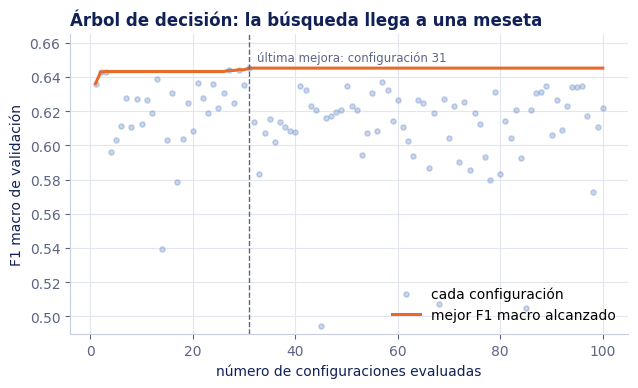

Mejor F1 macro: 0.6451 (configuración 31 de 100) | a la mitad (50 configuraciones) ya se tenía 0.6451 | mejora en la segunda mitad: +0.0000


In [11]:
graficar_meseta(RES["Árbol de decisión"], "Árbol de decisión: la búsqueda llega a una meseta")

**Lectura.** El mejor árbol llega a un F1 macro de 0.645 (desv. 0.010) con criterio `entropy`, profundidad máxima 8, al menos 32 estudiantes por hoja, poda `ccp_alpha` ≈ 0.0016, pesos `balanced` y nominales en one-hot. Los cinco mejores están entre 0.643 y 0.645, así que las diferencias entre criterios, codificaciones y profundidades son menores que la desviación entre pliegues. La curva es plana desde la configuración 31: ninguna de las 69 siguientes la supera.

Lo que sí pesa son los pesos por clase: los cinco mejores usan `balanced` o Enrolled ×2. El árbol es el único que recupera bien a los inscritos (sensibilidad 0.63), pero a costa de marcar a muchos estudiantes como Enrolled (especificidad 0.74).

---

## 3. Naive Bayes

Naive Bayes no es un único modelo: la variante depende de cómo se **representa** cada atributo, y por eso el preprocesamiento cambia con ella. La búsqueda recorre cinco variantes:

| Variante | Preprocesamiento | Justificación |
|---|---|---|
| **Gaussiano** | Nominales en one-hot; numéricos tal cual o con `PowerTransformer` (Yeo-Johnson) | Supone que cada numérico sigue una campana dentro de cada clase; muchos atributos están muy sesgados (unidades aprobadas, notas con muchos ceros), y la transformación los acerca a una normal |
| **Categórico** | Numéricos discretizados con `KBinsDiscretizer` por cuantiles; nominales con `OrdinalEncoder` (categorías raras agrupadas y categorías nuevas en un valor aparte) | Estima una tabla de frecuencias por categoría y no supone ninguna forma de distribución |
| **Multinomial** y **Complemento** | Nominales en one-hot; numéricos reescalados a [0, 1] con `MinMaxScaler(clip=True)` | Piden entradas no negativas. Complemento está pensado para clases desbalanceadas |
| **Bernoulli** | Numéricos discretizados y todo en indicadores 0/1 | Modela la presencia o ausencia de cada característica |

**Espacio de búsqueda** (100 configuraciones, repartidas al azar entre las variantes):

| Hiperparámetro | Valores |
|---|---|
| Variante | gaussiano, categórico, multinomial, complemento, Bernoulli |
| Suavizado de Laplace `alpha` (categórico, multinomial, complemento, Bernoulli) | continuo, escala logarítmica de 0.01 a 10 |
| `var_smoothing` (gaussiano) | continuo, escala logarítmica de 1e-10 a 1e-1 |
| Transformación de los numéricos (gaussiano) | ninguna o `PowerTransformer` |
| Número de bins (categórico, Bernoulli) | 3, 4, 5, 6, 8 o 10 |
| A priori de las clases (`fit_prior` o `priors` uniformes; `norm` en complemento) | sí o no |
| Categorías raras agrupadas (`min_frequency`) | 10, 30 o 100 |

Naive Bayes no admite `class_weight`; el equivalente es fijar a priori uniformes, que también está en el espacio.

In [12]:
def construir_nb(p, num=NUMERICOS):
    v = p["variante"]
    if v == "gaussiano":
        num_tr = PowerTransformer() if p["transformar"] else "passthrough"
        prep = ColumnTransformer([("nom", onehot(p["min_freq"]), NOMINALES), ("num", num_tr, num)],
                                 remainder="passthrough")
        priors = [1 / 3] * 3 if p["priors_uniformes"] else None
        clf = GaussianNB(var_smoothing=p["var_smoothing"], priors=priors)
    elif v == "categorico":
        nom = Pipeline([("ord", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1,
                                               min_frequency=p["min_freq"])),
                        ("mas1", FunctionTransformer(mas_uno))])       # CategoricalNB exige valores >= 0
        disc = KBinsDiscretizer(n_bins=p["n_bins"], encode="ordinal", strategy="quantile",
                                quantile_method="averaged_inverted_cdf")
        prep = ColumnTransformer([("nom", nom, NOMINALES), ("num", disc, num)], remainder="passthrough")
        clf = CategoricalNB(alpha=p["alpha"], fit_prior=p["fit_prior"])
    elif v in ("multinomial", "complemento"):
        prep = ColumnTransformer([("nom", onehot(p["min_freq"]), NOMINALES),
                                  ("num", MinMaxScaler(clip=True), num)], remainder="passthrough")
        clf = (MultinomialNB(alpha=p["alpha"], fit_prior=p["fit_prior"]) if v == "multinomial"
               else ComplementNB(alpha=p["alpha"], norm=p["norm"]))
    else:                                                               # bernoulli
        disc = KBinsDiscretizer(n_bins=p["n_bins"], encode="onehot-dense", strategy="quantile",
                                quantile_method="averaged_inverted_cdf")
        prep = ColumnTransformer([("nom", onehot(p["min_freq"]), NOMINALES), ("num", disc, num)],
                                 remainder="passthrough")
        clf = BernoulliNB(alpha=p["alpha"], fit_prior=p["fit_prior"])
    return Pipeline([("prep", prep), ("nb", clf)])


ESPACIO_NB = [
    dict(variante=["gaussiano"], min_freq=[10, 30, 100], transformar=[False, True],
         var_smoothing=loguniform(1e-10, 1e-1), priors_uniformes=[False, True]),
    dict(variante=["categorico"], min_freq=[10, 30, 100], n_bins=[3, 4, 5, 6, 8, 10],
         alpha=loguniform(1e-2, 10), fit_prior=[True, False]),
    dict(variante=["multinomial"], min_freq=[10, 30, 100], alpha=loguniform(1e-2, 10), fit_prior=[True, False]),
    dict(variante=["complemento"], min_freq=[10, 30, 100], alpha=loguniform(1e-2, 10), norm=[False, True]),
    dict(variante=["bernoulli"], min_freq=[10, 30, 100], n_bins=[3, 4, 5, 6, 8, 10],
         alpha=loguniform(1e-2, 10), fit_prior=[True, False]),
]

FAB["Naive Bayes"] = (construir_nb, ESPACIO_NB)
RES["Naive Bayes"] = buscar(construir_nb, ESPACIO_NB)
print(f"Configuraciones evaluadas: {RES['Naive Bayes']['n_config']} | tiempo de la búsqueda: {RES['Naive Bayes']['tiempo']:.1f} s")
mostrar_mejores(RES["Naive Bayes"], ["variante", "min_freq", "n_bins", "alpha", "var_smoothing", "transformar", "fit_prior", "priors_uniformes", "norm"])

Configuraciones evaluadas: 100 | tiempo de la búsqueda: 35.0 s


,config,f1_media,f1_sd,variante,min_freq,n_bins,alpha,var_smoothing,transformar,fit_prior,priors_uniformes,norm
0,5,0.6253,0.0073,categorico,10,6,0.035114,None,None,True,None,None
1,11,0.6195,0.0076,categorico,10,4,0.143301,None,None,False,None,None
2,16,0.6184,0.0163,categorico,30,6,0.223492,None,None,False,None,None
3,46,0.6182,0.0162,categorico,30,6,0.391565,None,None,False,None,None
4,54,0.6177,0.0117,categorico,30,5,5.944028,None,None,False,None,None


             configuraciones   mejor  mediana
variante                                     
categorico                16  0.6253   0.6163
bernoulli                 22  0.6163   0.6070
gaussiano                 11  0.5808   0.4943
complemento               26  0.5392   0.4485
multinomial               25  0.5366   0.5252


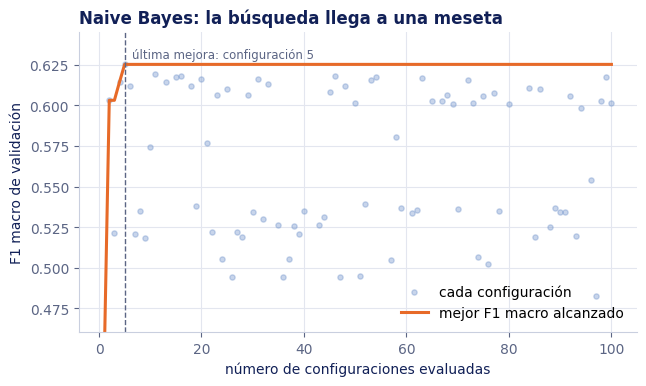

Mejor F1 macro: 0.6253 (configuración 5 de 100) | a la mitad (50 configuraciones) ya se tenía 0.6253 | mejora en la segunda mitad: +0.0000
(20 configuraciones con F1 macro por debajo de 0.47 quedan fuera del recuadro de la gráfica)


In [13]:
# F1 macro por variante: mejor configuración de cada una
t_nb = RES["Naive Bayes"]["tabla"].copy()
t_nb["variante"] = [p["variante"] for p in t_nb["params"]]
resumen_variantes = (t_nb.groupby("variante")["f1_media"].agg(configuraciones="size", mejor="max", mediana="median")
                     .sort_values("mejor", ascending=False).round(4))
print(resumen_variantes.to_string())
graficar_meseta(RES["Naive Bayes"], "Naive Bayes: la búsqueda llega a una meseta")

**Lectura.** La mejor configuración es Naive Bayes **categórico** (numéricos en 6 bins por cuantiles, `alpha` ≈ 0.035, a priori estimados de los datos), con F1 macro de 0.625 (desv. 0.007). La representación importa más que el suavizado: el mejor categórico (0.625) y el mejor de Bernoulli (0.616) superan por mucho al gaussiano (0.581), al complemento (0.539) y al multinomial (0.537), cuyas medianas quedan por debajo de 0.53. El gaussiano falla porque muchos numéricos (unidades aprobadas, notas con muchos ceros) no son campanas, y el multinomial y el complemento esperan conteos, no una mezcla de notas, edades y bandas.

El límite del modelo es el supuesto de independencia: las variables del primer semestre están muy relacionadas entre sí y Naive Bayes las cuenta como evidencia independiente. Detecta bien a los desertores (sensibilidad 0.70), pero con casi 16 % de falsas alarmas (especificidad 0.84) y recupera poco a Enrolled (0.42). La mejor configuración apareció en la quinta de las 100, y ninguna posterior la superó.

---

## 4. k vecinos más cercanos (kNN)

**Preprocesamiento (dentro del Pipeline).**

- **Escalamiento:** kNN decide con distancias, así que un atributo con rango grande (por ejemplo, las notas de 0 a 200) pesaría más que uno de rango pequeño. Los numéricos y los binarios se reescalan con `StandardScaler` o con `MinMaxScaler`, y la búsqueda elige.
- **Nominales:** one-hot con categorías raras agrupadas. Con códigos enteros la distancia entre `Course` 3 y `Course` 4 sería 1 y entre 3 y 17, 14, lo cual no significa nada. Como una categoría activa aporta mucha distancia, se agrega un **peso del bloque nominal** (0.25, 0.5 o 1) para que los 9 atributos nominales no dominen a los 21 restantes.

**Espacio de búsqueda** (100 configuraciones):

| Hiperparámetro | Valores |
|---|---|
| Número de vecinos `k` | entero entre 1 y 120 |
| Ponderación de los votos | uniforme o por inverso de la distancia |
| Distancia | euclidiana, Manhattan o coseno |
| Escalador | estándar o min-máx |
| Peso del bloque nominal | 0.25, 0.5 o 1 |
| Categorías raras agrupadas (`min_frequency`) | 10, 30 o 100 |

kNN no admite `class_weight`.

In [14]:
def construir_knn(p, num=NUMERICOS):
    esc = StandardScaler() if p["escalador"] == "estandar" else MinMaxScaler()
    prep = ColumnTransformer([("nom", onehot(p["min_freq"]), NOMINALES), ("num", esc, num + BINARIOS)],
                             transformer_weights={"nom": p["peso_nominal"], "num": 1.0})
    clf = KNeighborsClassifier(n_neighbors=p["n_neighbors"], weights=p["weights"], metric=p["metric"])
    return Pipeline([("prep", prep), ("knn", clf)])


ESPACIO_KNN = [dict(escalador=["estandar", "minmax"], min_freq=[10, 30, 100], peso_nominal=[0.25, 0.5, 1.0],
                    n_neighbors=randint(1, 121), weights=["uniform", "distance"],
                    metric=["euclidean", "manhattan", "cosine"])]

FAB["kNN"] = (construir_knn, ESPACIO_KNN)
RES["kNN"] = buscar(construir_knn, ESPACIO_KNN)
print(f"Configuraciones evaluadas: {RES['kNN']['n_config']} | tiempo de la búsqueda: {RES['kNN']['tiempo']:.1f} s")
mostrar_mejores(RES["kNN"], ["escalador", "min_freq", "peso_nominal", "n_neighbors", "weights", "metric"])

Configuraciones evaluadas: 100 | tiempo de la búsqueda: 95.2 s


,config,f1_media,f1_sd,escalador,min_freq,peso_nominal,n_neighbors,weights,metric
0,97,0.5820,0.0225,estandar,30,0.50,19,distance,manhattan
1,98,0.5801,0.0209,estandar,10,1.00,4,distance,euclidean
2,20,0.5795,0.0117,estandar,100,1.00,11,uniform,euclidean
3,81,0.5744,0.0165,estandar,10,0.25,8,distance,euclidean
4,65,0.5692,0.0101,estandar,10,0.50,17,uniform,cosine


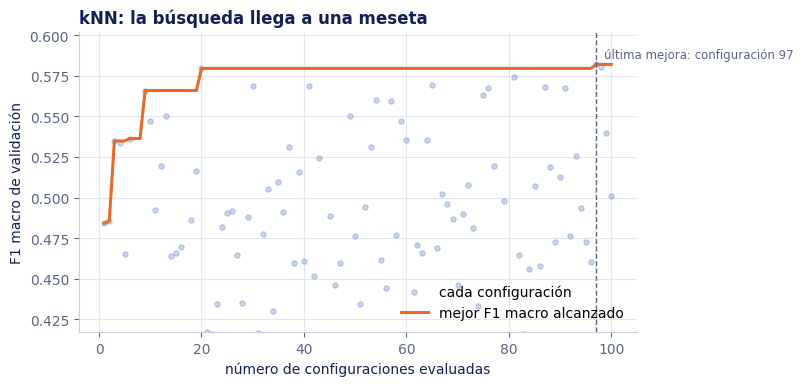

Mejor F1 macro: 0.5820 (configuración 97 de 100) | a la mitad (50 configuraciones) ya se tenía 0.5795 | mejora en la segunda mitad: +0.0025
(12 configuraciones con F1 macro por debajo de 0.42 quedan fuera del recuadro de la gráfica)


In [15]:
graficar_meseta(RES["kNN"], "kNN: la búsqueda llega a una meseta")

**Lectura.** kNN es el más débil: F1 macro de 0.582 (desv. 0.023, la mayor de los cinco). Su mejor configuración usa `k` = 19, votos ponderados por distancia, distancia Manhattan, escalado estándar y un peso de 0.5 para el bloque nominal. Las cinco mejores están entre 0.569 y 0.582 y todas usan escalado estándar; la ponderación por distancia aparece en tres. La búsqueda llega a una meseta: en la segunda mitad solo mejora 0.0025.

La limitación es estructural. Con 17.9 % de inscritos y sin `class_weight`, los vecinos de casi cualquier estudiante son mayoritariamente Graduate o Dropout, y la sensibilidad de Enrolled se queda en 0.16 (contra 0.96 de Graduate). Además, con 30 atributos, varios poco informativos, las distancias se vuelven poco discriminantes.

---

## 5. Máquinas de soporte vectorial (SVM)

**Preprocesamiento (dentro del Pipeline).**

- **Escalamiento:** el SVM depende de productos punto y distancias, y el parámetro `gamma` supone que todos los atributos tienen una escala comparable. Los numéricos y los binarios se estandarizan con `StandardScaler`.
- **Nominales:** one-hot con categorías raras agrupadas, por la misma razón que en kNN.
- **Sin discretización:** el SVM trabaja con atributos continuos.

**Espacio de búsqueda** (100 configuraciones, repartidas al azar entre los cuatro kernels):

| Kernel | `C` (escala logarítmica) | `gamma` (escala logarítmica) | Otros |
|---|---|---|---|
| Lineal | 0.001 a 10 | no aplica | |
| RBF | 0.1 a 1000 | 1e-4 a 0.3 | |
| Polinomial | 0.01 a 100 | 1e-4 a 0.1 | grado 2 o 3, `coef0` 0 o 1 |
| Sigmoide | 0.01 a 100 | 1e-4 a 0.01 | `coef0` 0 o 1 |

En todos: pesos por clase (ninguno, `balanced`, Enrolled ×2, Enrolled ×3) y categorías raras agrupadas (`min_frequency` de 10, 30 o 100).

In [16]:
def construir_svm(p, num=NUMERICOS):
    prep = ColumnTransformer([("nom", onehot(p["min_freq"]), NOMINALES),
                              ("num", StandardScaler(), num + BINARIOS)])
    kw = dict(kernel=p["kernel"], C=p["C"], class_weight=p["class_weight"], cache_size=500, random_state=SEMILLA)
    for k in ("gamma", "degree", "coef0"):
        if k in p:
            kw[k] = p[k]
    return Pipeline([("prep", prep), ("svm", SVC(**kw))])


_base = dict(min_freq=[10, 30, 100], class_weight=PESOS)
ESPACIO_SVM = [
    dict(_base, kernel=["linear"], C=loguniform(1e-3, 1e1)),
    dict(_base, kernel=["rbf"], C=loguniform(1e-1, 1e3), gamma=loguniform(1e-4, 3e-1)),
    dict(_base, kernel=["poly"], C=loguniform(1e-2, 1e2), gamma=loguniform(1e-4, 1e-1), degree=[2, 3], coef0=[0.0, 1.0]),
    dict(_base, kernel=["sigmoid"], C=loguniform(1e-2, 1e2), gamma=loguniform(1e-4, 1e-2), coef0=[0.0, 1.0]),
]

FAB["SVM"] = (construir_svm, ESPACIO_SVM)
RES["SVM"] = buscar(construir_svm, ESPACIO_SVM)
print(f"Configuraciones evaluadas: {RES['SVM']['n_config']} | tiempo de la búsqueda: {RES['SVM']['tiempo']:.1f} s")
mostrar_mejores(RES["SVM"], ["kernel", "C", "gamma", "degree", "coef0", "class_weight", "min_freq"])

Configuraciones evaluadas: 100 | tiempo de la búsqueda: 693.1 s


,config,f1_media,f1_sd,kernel,C,gamma,degree,coef0,class_weight,min_freq
0,68,0.6886,0.0092,rbf,172.760567,0.000778,NaN,NaN,"{0: 1.0, 1: 2.0, 2: 1.0}",10
1,44,0.6782,0.0102,poly,2.309786,0.013597,2.0,1.0,"{0: 1.0, 1: 2.0, 2: 1.0}",100
2,46,0.6762,0.0134,rbf,224.305759,0.001534,NaN,NaN,"{0: 1.0, 1: 2.0, 2: 1.0}",10
3,24,0.6727,0.0078,linear,0.175836,NaN,NaN,NaN,"{0: 1.0, 1: 2.0, 2: 1.0}",30
4,89,0.6727,0.0162,rbf,31.874227,0.005523,NaN,NaN,balanced,10


         configuraciones   mejor  mediana
kernel                                   
rbf                   22  0.6886   0.6268
poly                  23  0.6782   0.5047
linear                20  0.6727   0.6605
sigmoid               35  0.6598   0.5972


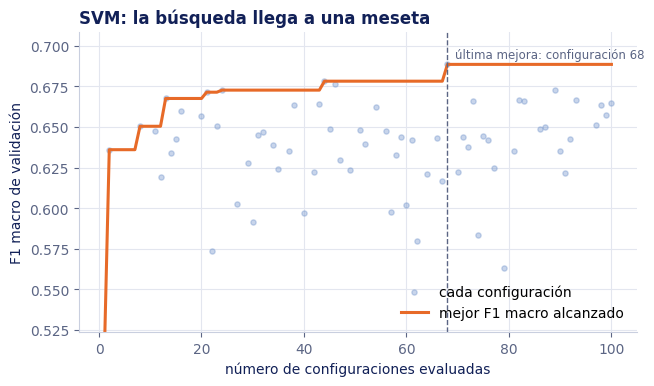

Mejor F1 macro: 0.6886 (configuración 68 de 100) | a la mitad (50 configuraciones) ya se tenía 0.6782 | mejora en la segunda mitad: +0.0103
(33 configuraciones con F1 macro por debajo de 0.53 quedan fuera del recuadro de la gráfica)


In [17]:
t_svm = RES["SVM"]["tabla"].copy()
t_svm["kernel"] = [p["kernel"] for p in t_svm["params"]]
print(t_svm.groupby("kernel")["f1_media"].agg(configuraciones="size", mejor="max", mediana="median")
      .sort_values("mejor", ascending=False).round(4).to_string())
graficar_meseta(RES["SVM"], "SVM: la búsqueda llega a una meseta")

**Lectura.** El SVM con kernel RBF es el mejor clasificador: F1 macro de 0.689 (desv. 0.009), con `C` ≈ 173, `gamma` ≈ 7.8e-4, pesos Enrolled ×2 y categorías con menos de 10 estudiantes agrupadas. Un `C` grande con un `gamma` muy pequeño produce una frontera casi lineal con una ligera curvatura; lo que cuenta es la combinación de ambos (`C · gamma` ≈ 0.13).

Por kernel, el mejor RBF obtiene 0.689, el polinomial de grado 2, 0.678, el lineal, 0.673 y el sigmoide, 0.660. Las medianas muestran quiénes son robustos: el lineal es el más estable (0.661), seguido del RBF (0.627), mientras que el polinomial (0.505) y el sigmoide (0.597) fallan con muchas combinaciones. Los cinco mejores usan pesos que refuerzan a Enrolled (×2 o `balanced`).

La curva llega a una meseta: mejora 0.010 en la segunda mitad (configuración 68) y ninguna de las últimas 32 configuraciones la supera. Como el espacio es grande (cuatro kernels), una ganancia adicional no se descarta, pero sería menor que la desviación entre pliegues. Fue la búsqueda más cara (320 s).

---

## 6. Regresión logística

**Preprocesamiento (dentro del Pipeline).**

- **Escalamiento:** la regresión logística se ajusta con métodos iterativos y se regulariza con una penalización sobre el tamaño de los coeficientes, que solo es justa si los atributos están en una escala comparable. Se estandarizan los numéricos y los binarios.
- **Nominales:** one-hot con categorías raras agrupadas, porque el modelo asigna un coeficiente a cada columna y un código entero obligaría a una relación lineal falsa con el número.

**Espacio de búsqueda** (100 configuraciones, repartidas al azar entre los cuatro tipos de regularización):

| Regularización | `C` (escala logarítmica) | Otros |
|---|---|---|
| Ninguna (`C = ∞`) | no aplica | |
| L2 (`lbfgs`) | 1e-4 a 100 | |
| L1 (`saga`) | 1e-3 a 100 | |
| Elastic net (`saga`) | 1e-3 a 100 | `l1_ratio` entre 0.1 y 0.9 |

En todos: pesos por clase (ninguno, `balanced`, Enrolled ×2, Enrolled ×3) y categorías raras agrupadas (`min_frequency` de 10, 30 o 100). Con tres clases, el modelo es multinomial (*softmax*).

In [18]:
def construir_lr(p, num=NUMERICOS):
    prep = ColumnTransformer([("nom", onehot(p["min_freq"]), NOMINALES),
                              ("num", StandardScaler(), num + BINARIOS)])
    reg = p["regularizacion"]
    if reg == "ninguna":
        kw = dict(penalty=None, solver="lbfgs")
    elif reg == "l2":
        kw = dict(C=p["C"], solver="lbfgs")
    elif reg == "l1":
        kw = dict(C=p["C"], penalty="l1", solver="saga")
    else:
        kw = dict(C=p["C"], penalty="elasticnet", l1_ratio=p["l1_ratio"], solver="saga")
    clf = LogisticRegression(max_iter=1000, tol=1e-3, class_weight=p["class_weight"], random_state=SEMILLA, **kw)
    return Pipeline([("prep", prep), ("logistica", clf)])


_base = dict(min_freq=[10, 30, 100], class_weight=PESOS)
ESPACIO_LR = [
    dict(_base, regularizacion=["ninguna"], C=[1.0]),
    dict(_base, regularizacion=["l2"], C=loguniform(1e-4, 1e2)),
    dict(_base, regularizacion=["l1"], C=loguniform(1e-3, 1e2)),
    dict(_base, regularizacion=["elasticnet"], C=loguniform(1e-3, 1e2), l1_ratio=uniform(0.1, 0.8)),
]

FAB["Regresión logística"] = (construir_lr, ESPACIO_LR)
RES["Regresión logística"] = buscar(construir_lr, ESPACIO_LR)
print(f"Configuraciones evaluadas: {RES['Regresión logística']['n_config']} | tiempo de la búsqueda: {RES['Regresión logística']['tiempo']:.1f} s")
mostrar_mejores(RES["Regresión logística"], ["regularizacion", "C", "l1_ratio", "class_weight", "min_freq"])

Configuraciones evaluadas: 100 | tiempo de la búsqueda: 662.9 s


,config,f1_media,f1_sd,regularizacion,C,l1_ratio,class_weight,min_freq
0,73,0.6815,0.0066,elasticnet,1.076825,0.397826,"{0: 1.0, 1: 2.0, 2: 1.0}",10
1,15,0.6808,0.0065,elasticnet,0.299147,0.238692,"{0: 1.0, 1: 2.0, 2: 1.0}",10
2,75,0.6791,0.0045,l2,0.081975,NaN,"{0: 1.0, 1: 2.0, 2: 1.0}",10
3,81,0.6788,0.0085,l2,27.327048,NaN,"{0: 1.0, 1: 2.0, 2: 1.0}",30
4,95,0.6779,0.0078,ninguna,1.000000,NaN,"{0: 1.0, 1: 2.0, 2: 1.0}",30


                configuraciones   mejor  mediana
regularizacion                                  
elasticnet                   30  0.6815   0.6664
l2                           22  0.6791   0.6636
ninguna                      18  0.6779   0.6652
l1                           30  0.6767   0.6616


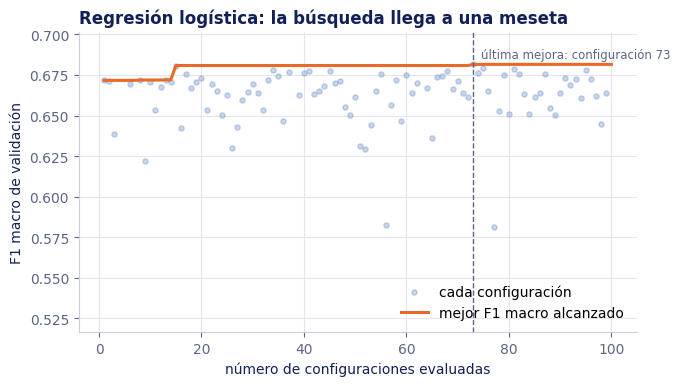

Mejor F1 macro: 0.6815 (configuración 73 de 100) | a la mitad (50 configuraciones) ya se tenía 0.6808 | mejora en la segunda mitad: +0.0007
(6 configuraciones con F1 macro por debajo de 0.52 quedan fuera del recuadro de la gráfica)


In [19]:
t_lr = RES["Regresión logística"]["tabla"].copy()
t_lr["regularizacion"] = [p["regularizacion"] for p in t_lr["params"]]
print(t_lr.groupby("regularizacion")["f1_media"].agg(configuraciones="size", mejor="max", mediana="median")
      .sort_values("mejor", ascending=False).round(4).to_string())
graficar_meseta(RES["Regresión logística"], "Regresión logística: la búsqueda llega a una meseta")

**Lectura.** La mejor regresión logística usa regularización *elastic net* (`l1_ratio` ≈ 0.40, `C` ≈ 1.08), pesos Enrolled ×2 y alcanza un F1 macro de 0.682 (desv. 0.007, la menor de los cinco). Los cuatro tipos de regularización quedan muy cerca: el mejor de cada uno está entre 0.677 y 0.682, y sin regularización llega a 0.678. Con 30 atributos y 3,539 estudiantes el modelo casi no sobreajusta, así que la penalización aporta poco; lo que sí aporta son los pesos por clase (los cinco mejores usan Enrolled ×2).

La curva es plana: el máximo prácticamente ya estaba en la configuración 15 (0.6808) y la mejora posterior fue de 0.0007. Es el más estable entre pliegues y el segundo mejor, a solo 0.007 del SVM.

---

## 7. Comparación de los cinco clasificadores optimizados

Para cada clasificador se toma su mejor configuración y se calculan, con los **mismos pliegues**, las predicciones de validación cruzada de todos los estudiantes (`cross_val_predict`). De ellas salen la sensibilidad (recall) y la especificidad de cada clase, calculadas en forma una-contra-todas. El F1 macro, con su media y desviación estándar entre pliegues, viene de la búsqueda.

In [20]:
def sens_esp(y_real, y_pred):
    cm = confusion_matrix(y_real, y_pred, labels=[0, 1, 2])
    out = {}
    for k, clase in enumerate(CLASES):
        tp = cm[k, k]
        fn = cm[k].sum() - tp
        fp = cm[:, k].sum() - tp
        tn = cm.sum() - tp - fn - fp
        out[f"sens. {clase}"] = tp / (tp + fn)
        out[f"esp. {clase}"] = tn / (tn + fp)
    return out


OOF = {}          # predicciones de validación cruzada del mejor modelo de cada clasificador
filas = {}
for nombre, res in RES.items():
    construir, _ = FAB[nombre]
    OOF[nombre] = cross_val_predict(construir(res["params"]), X, y, cv=PLIEGUES)
    filas[nombre] = {"F1 macro (media)": res["f1_media"], "F1 macro (desv.)": res["f1_sd"],
                     **sens_esp(y, OOF[nombre]), "tiempo de búsqueda (s)": res["tiempo"]}

comparacion = pd.DataFrame(filas).T.sort_values("F1 macro (media)", ascending=False)
formato = {c: "{:.3f}".format for c in comparacion.columns}
formato["tiempo de búsqueda (s)"] = "{:.1f}".format
print(comparacion.to_string(formatters=formato))

                    F1 macro (media) F1 macro (desv.) sens. Dropout esp. Dropout sens. Enrolled esp. Enrolled sens. Graduate esp. Graduate tiempo de búsqueda (s)
SVM                            0.689            0.009         0.654        0.945          0.559         0.848          0.856         0.801                  693.1
Regresión logística            0.682            0.007         0.676        0.933          0.531         0.848          0.839         0.804                  662.9
Árbol de decisión              0.645            0.010         0.600        0.953          0.633         0.743          0.742         0.839                   43.7
Naive Bayes                    0.625            0.007         0.704        0.843          0.417         0.870          0.759         0.787                   35.0
kNN                            0.582            0.023         0.615        0.942          0.164         0.962          0.955         0.549                   95.2


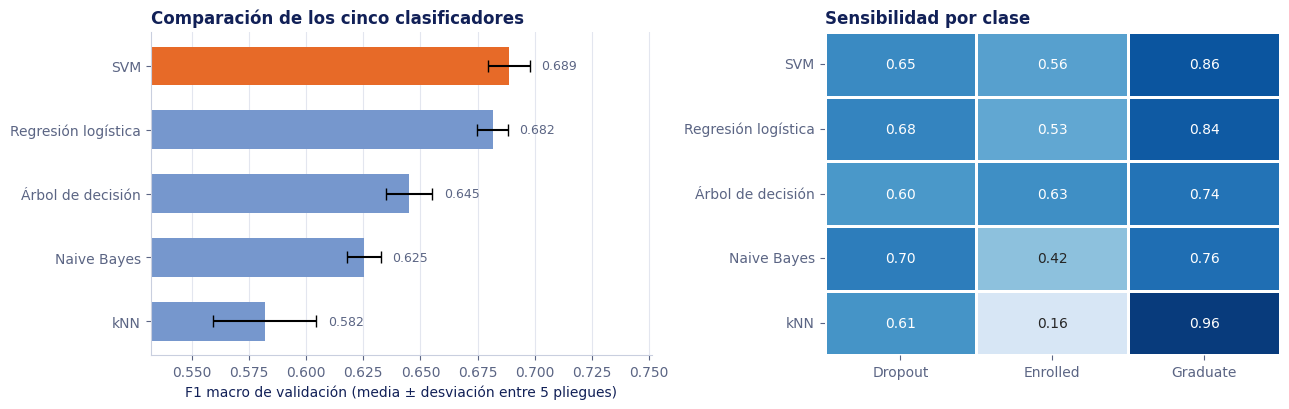

In [21]:
orden = comparacion.index.tolist()
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1.1, 1]})

axes[0].barh(orden[::-1], comparacion["F1 macro (media)"][::-1], xerr=comparacion["F1 macro (desv.)"][::-1],
             color=[NARANJA if n == orden[0] else AZUL for n in orden[::-1]], capsize=4, height=0.6)
for i, n in enumerate(orden[::-1]):
    axes[0].text(comparacion.loc[n, "F1 macro (media)"] + comparacion.loc[n, "F1 macro (desv.)"] + 0.005, i,
                 f"{comparacion.loc[n, 'F1 macro (media)']:.3f}", va="center", color=GRIS, fontsize=9)
axes[0].set_xlim(comparacion["F1 macro (media)"].min() - 0.05, comparacion["F1 macro (media)"].max() + comparacion["F1 macro (desv.)"].max() + 0.04)
axes[0].set_xlabel("F1 macro de validación (media ± desviación entre 5 pliegues)")
axes[0].set_title("Comparación de los cinco clasificadores")
axes[0].grid(axis="y", visible=False)

sens = comparacion[[f"sens. {c}" for c in CLASES]]
sens.columns = CLASES
sns.heatmap(sens, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, cbar=False, linewidths=1, ax=axes[1])
axes[1].set_title("Sensibilidad por clase")
axes[1].grid(False)
plt.tight_layout()
plt.show()

### Verificación con pliegues nuevos

Como la mejor configuración de cada clasificador se escogió entre 100 mirando los mismos 5 pliegues, su F1 macro tiende a ser un poco optimista. Para comprobar que el orden no depende de esos pliegues concretos, se vuelve a evaluar cada configuración ganadora con **15 pliegues nuevos** (5 pliegues repetidos 3 veces, con otra semilla). Esta tabla no cambia la elección; sirve como contraste.

In [22]:
pliegues_nuevos = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEMILLA + 1)
nuevos = {}
for nombre, res in RES.items():
    construir, _ = FAB[nombre]
    r = cross_validate(construir(res["params"]), X, y, cv=pliegues_nuevos, scoring="f1_macro")
    nuevos[nombre] = {"F1 macro, pliegues originales": res["f1_media"],
                      "F1 macro, pliegues nuevos (media)": r["test_score"].mean(),
                      "F1 macro, pliegues nuevos (desv.)": r["test_score"].std()}
verificacion = pd.DataFrame(nuevos).T.sort_values("F1 macro, pliegues nuevos (media)", ascending=False)
verificacion["diferencia"] = verificacion["F1 macro, pliegues nuevos (media)"] - verificacion["F1 macro, pliegues originales"]
print(verificacion.round(4).to_string())

                     F1 macro, pliegues originales  F1 macro, pliegues nuevos (media)  F1 macro, pliegues nuevos (desv.)  diferencia
SVM                                         0.6886                             0.6850                             0.0188     -0.0035
Regresión logística                         0.6815                             0.6775                             0.0171     -0.0040
Árbol de decisión                           0.6451                             0.6409                             0.0215     -0.0042
Naive Bayes                                 0.6253                             0.6253                             0.0207      0.0000
kNN                                         0.5820                             0.5701                             0.0214     -0.0119


**Lectura.** El SVM (0.689) y la regresión logística (0.682) encabezan la comparación, separados por menos de una desviación entre pliegues (0.009 y 0.007). Con pliegues nuevos, el SVM sigue arriba (0.685 contra 0.678) y el orden de los cinco se conserva: después van el árbol (0.645), Naive Bayes (0.625) y kNN (0.582). Con los pliegues nuevos todos bajan entre 0.000 y 0.012, que es el optimismo esperable de escoger la mejor entre 100 configuraciones.

Cada clasificador tiene un perfil distinto. Naive Bayes es el que más desertores detecta (0.70) pero con más falsas alarmas; el árbol recupera mejor a los inscritos (0.63) a costa de los graduados (0.74); kNN casi ignora a Enrolled (0.16); el SVM y la regresión logística logran el mejor equilibrio. En todos, Enrolled es la clase más difícil y Graduate la más fácil. También cambia el costo: el árbol, Naive Bayes y kNN se optimizan en menos de un minuto, mientras que la regresión logística tarda 205 s y el SVM, 320 s. El clasificador final es el SVM.

---

## 8. El mejor clasificador: matriz de confusión y la clase *Dropout*

Mejor clasificador: SVM
Mejores hiperparámetros: {'C': np.float64(172.76056747028196), 'class_weight': {0: 1.0, 1: 2.0, 2: 1.0}, 'gamma': np.float64(0.0007777904549497886), 'kernel': 'rbf', 'min_freq': 10}


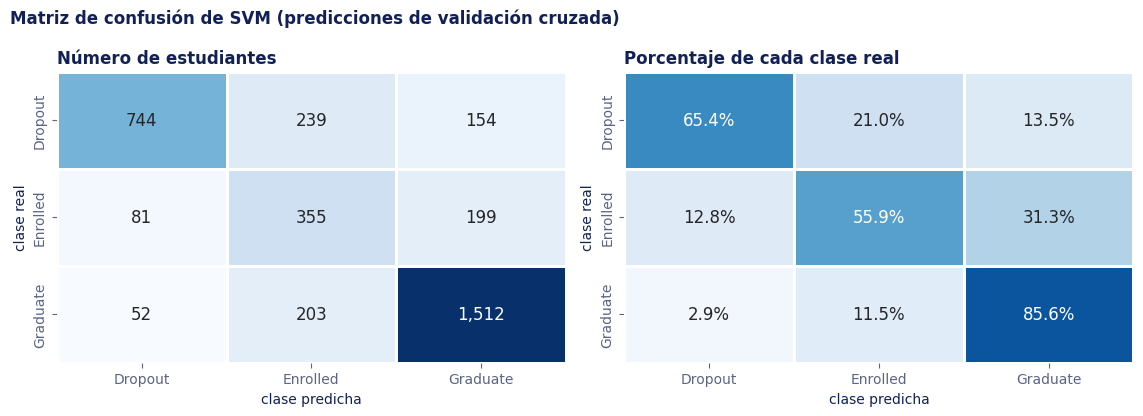

De 1137 desertores reales: 744 bien clasificados (65.4%), 239 confundidos con Enrolled (21.0%) y 154 con Graduate (13.5%).
De 877 estudiantes predichos como Dropout: 744 lo eran (84.8%); 81 eran Enrolled y 52 eran Graduate.


In [23]:
mejor_nombre = comparacion.index[0]
print("Mejor clasificador:", mejor_nombre)
print("Mejores hiperparámetros:", {k: v for k, v in RES[mejor_nombre]["params"].items()})

y_oof = OOF[mejor_nombre]
cm = confusion_matrix(y, y_oof, labels=[0, 1, 2])
cm_norm = cm / cm.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2))
sns.heatmap(pd.DataFrame(cm, index=CLASES, columns=CLASES), annot=True, fmt=",d", cmap="Blues", cbar=False,
            linewidths=1, annot_kws={"fontsize": 12}, ax=axes[0])
axes[0].set_title("Número de estudiantes")
sns.heatmap(pd.DataFrame(cm_norm, index=CLASES, columns=CLASES), annot=True, fmt=".1%", cmap="Blues", cbar=False,
            linewidths=1, annot_kws={"fontsize": 12}, vmin=0, vmax=1, ax=axes[1])
axes[1].set_title("Porcentaje de cada clase real")
for ax in axes:
    ax.set_xlabel("clase predicha")
    ax.set_ylabel("clase real")
    ax.grid(False)
fig.suptitle(f"Matriz de confusión de {mejor_nombre} (predicciones de validación cruzada)", x=0.01, ha="left",
             color=AZUL_OSCURO, fontweight="bold")
plt.tight_layout()
plt.show()

d = cm[0]
print(f"De {d.sum()} desertores reales: {d[0]} bien clasificados ({d[0] / d.sum():.1%}), "
      f"{d[1]} confundidos con Enrolled ({d[1] / d.sum():.1%}) y {d[2]} con Graduate ({d[2] / d.sum():.1%}).")
col = cm[:, 0]
print(f"De {col.sum()} estudiantes predichos como Dropout: {col[0]} lo eran ({col[0] / col.sum():.1%}); "
      f"{col[1]} eran Enrolled y {col[2]} eran Graduate.")

In [24]:
# ¿En qué se parecen los desertores mal clasificados a la clase con la que se confunden?
variables = ["Curricular units 1st sem (approved)", "Curricular units 1st sem (grade)",
             "Curricular units 1st sem (enrolled)", "Curricular units 1st sem (without evaluations)",
             "Tuition fees up to date", "Debtor", "Scholarship holder", "Age at enrollment", "Admission grade"]
corto = {"Curricular units 1st sem (approved)": "aprobadas 1.er sem.", "Curricular units 1st sem (grade)": "nota media 1.er sem.",
         "Curricular units 1st sem (enrolled)": "inscritas 1.er sem.",
         "Curricular units 1st sem (without evaluations)": "sin evaluar 1.er sem.",
         "Tuition fees up to date": "colegiatura al día", "Debtor": "deudor", "Scholarship holder": "becario",
         "Age at enrollment": "edad al ingresar", "Admission grade": "nota de admisión"}

es_dropout = y == 0
grupos = {
    "Dropout detectado": X[es_dropout & (y_oof == 0)][variables].mean(),
    "Dropout → Enrolled": X[es_dropout & (y_oof == 1)][variables].mean(),
    "Dropout → Graduate": X[es_dropout & (y_oof == 2)][variables].mean(),
    "Enrolled (real)": X[y == 1][variables].mean(),
    "Graduate (real)": X[y == 2][variables].mean(),
}
perfil = pd.DataFrame(grupos).rename(index=corto).round(2)
perfil.loc["estudiantes"] = [int((es_dropout & (y_oof == 0)).sum()), int((es_dropout & (y_oof == 1)).sum()),
                             int((es_dropout & (y_oof == 2)).sum()), int((y == 1).sum()), int((y == 2).sum())]
print(perfil.to_string())

                       Dropout detectado  Dropout → Enrolled  Dropout → Graduate  Enrolled (real)  Graduate (real)
aprobadas 1.er sem.                 1.66                3.40                5.58             4.33             6.25
nota media 1.er sem.                5.48               10.84               10.96            11.13            12.62
inscritas 1.er sem.                 5.80                5.79                6.07             6.01             6.68
sin evaluar 1.er sem.               0.23                0.16                0.12             0.19             0.09
colegiatura al día                  0.51                0.97                0.99             0.95             0.99
deudor                              0.30                0.09                0.07             0.11             0.04
becario                             0.06                0.08                0.29             0.17             0.38
edad al ingresar                   27.65               22.92               23.39

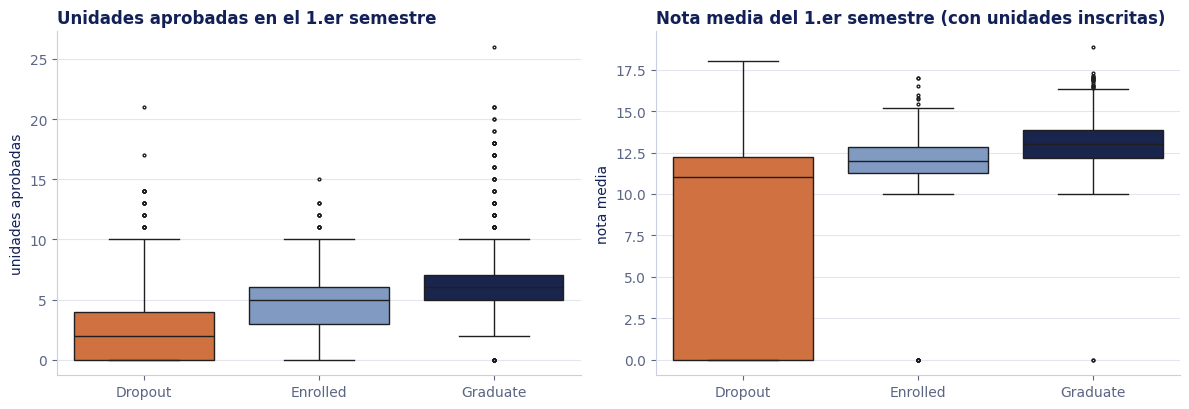

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
etiquetas = np.array(CLASES)[y]
sns.boxplot(x=etiquetas, y=X["Curricular units 1st sem (approved)"], order=CLASES, hue=etiquetas, hue_order=CLASES,
            palette=[NARANJA, AZUL, AZUL_OSCURO], legend=False, ax=axes[0], fliersize=2)
axes[0].set_title("Unidades aprobadas en el 1.er semestre")
axes[0].set_xlabel("")
axes[0].set_ylabel("unidades aprobadas")
datos = X[X["Curricular units 1st sem (enrolled)"] > 0]
etiq2 = np.array(CLASES)[y[datos.index]]
sns.boxplot(x=etiq2, y=datos["Curricular units 1st sem (grade)"], order=CLASES, hue=etiq2, hue_order=CLASES,
            palette=[NARANJA, AZUL, AZUL_OSCURO], legend=False, ax=axes[1], fliersize=2)
axes[1].set_title("Nota media del 1.er semestre (con unidades inscritas)")
axes[1].set_xlabel("")
axes[1].set_ylabel("nota media")
plt.tight_layout()
plt.show()

**Lectura.** El SVM detecta 744 de los 1,137 desertores (65.4 %). Confunde 239 (21.0 %) con Enrolled y 154 (13.5 %) con Graduate. Cuando predice *Dropout* acierta el 84.8 % de las veces (744 de 877), así que se equivoca más por omisión que por falsa alarma.

La tabla de perfiles explica por qué. Los desertores detectados tienen un primer semestre muy pobre (1.7 unidades aprobadas y nota media de 5.5), y son mayores (27.7 años al ingresar contra 23 de los demás): el 39.4 % de todos los desertores no aprobó ninguna unidad y de ellos se detecta el 90.2 %. En cambio, los que se confunden con Enrolled (3.4 unidades aprobadas, nota de 10.8, colegiatura al día en 97 % y solo 9 % deudores) son casi indistinguibles de los inscritos reales (4.3, 11.1, 95 % y 11 %), y los que se confunden con Graduate (5.6 unidades, nota de 11.0, 29 % becarios) se parecen a los graduados (6.3, 12.6, 38 %). El 60.6 % de los desertores sí aprobó alguna unidad, y entre ellos solo se detecta el 49.3 %.

Hay, pues, dos tipos de desertor: el que ya muestra el fracaso académico en el primer semestre, que es fácil de ver, y el que abandona con calificaciones aceptables y sus pagos al día, cuyas razones probablemente no están en los 30 atributos disponibles. Dropout y Enrolled comparten además un grupo grande de estudiantes con desempeño intermedio (el diagrama de caja de las unidades aprobadas muestra el traslape), por lo que ningún clasificador puede separarlos del todo con esta información.

---

## 9. ¿Conviene esperar al cierre del segundo semestre?

Con el conjunto de entrenamiento se estima cuánto ganaría el mejor clasificador si, además de los 30 atributos del primer semestre, se conocieran los 6 del segundo. Se hacen dos estimaciones con los **mismos pliegues**:

1. **Misma configuración:** el mismo modelo, con las mismas opciones, ahora con 36 atributos. Mide la ganancia de la información adicional por sí sola.
2. **Reoptimizada:** una nueva búsqueda de 60 configuraciones con los 36 atributos. Es una cota más justa para lo que se obtendría si realmente se esperara.

In [26]:
construir_mejor, espacio_mejor = FAB[mejor_nombre]
X2 = tr[ATRIBUTOS + SEGUNDO_SEM]
NUMERICOS_2 = NUMERICOS + SEGUNDO_SEM

# 1) misma configuración, con y sin el segundo semestre (mismos pliegues)
p_mejor = RES[mejor_nombre]["params"]
r1 = cross_validate(construir_mejor(p_mejor), X, y, cv=PLIEGUES, scoring="f1_macro")
r2 = cross_validate(construir_mejor(p_mejor, num=NUMERICOS_2), X2, y, cv=PLIEGUES, scoring="f1_macro")

# 2) nueva búsqueda con los 36 atributos
res2 = buscar(construir_mejor, espacio_mejor, n_iter=60, X_=X2, num=NUMERICOS_2)

oof_mismo = cross_val_predict(construir_mejor(p_mejor, num=NUMERICOS_2), X2, y, cv=PLIEGUES)
oof2 = cross_val_predict(construir_mejor(res2["params"], num=NUMERICOS_2), X2, y, cv=PLIEGUES)
dif = r2["test_score"] - r1["test_score"]

estimacion = pd.DataFrame({
    "1.er semestre (30 atributos)": {"F1 macro (media)": r1["test_score"].mean(), "F1 macro (desv.)": r1["test_score"].std(),
                                     **{f"sens. {c}": sens_esp(y, y_oof)[f"sens. {c}"] for c in CLASES}},
    "+ 2.º semestre, misma configuración": {"F1 macro (media)": r2["test_score"].mean(), "F1 macro (desv.)": r2["test_score"].std(),
                                            **{f"sens. {c}": sens_esp(y, oof_mismo)[f"sens. {c}"] for c in CLASES}},
    "+ 2.º semestre, reoptimizado": {"F1 macro (media)": res2["f1_media"], "F1 macro (desv.)": res2["f1_sd"],
                                     **{f"sens. {c}": sens_esp(y, oof2)[f"sens. {c}"] for c in CLASES}},
}).T
print(estimacion.round(3).to_string())
print(f"\nGanancia con la misma configuración: {dif.mean():+.3f} de F1 macro (desv. de la diferencia entre pliegues: {dif.std():.3f}; "
      f"mejora en {int((dif > 0).sum())} de 5 pliegues)")
print(f"Ganancia reoptimizando: {res2['f1_media'] - r1['test_score'].mean():+.3f} de F1 macro")

                                     F1 macro (media)  F1 macro (desv.)  sens. Dropout  sens. Enrolled  sens. Graduate
1.er semestre (30 atributos)                    0.689             0.009          0.654           0.559           0.856
+ 2.º semestre, misma configuración             0.717             0.009          0.699           0.589           0.869
+ 2.º semestre, reoptimizado                    0.713             0.016          0.723           0.557           0.862

Ganancia con la misma configuración: +0.028 de F1 macro (desv. de la diferencia entre pliegues: 0.011; mejora en 5 de 5 pliegues)
Ganancia reoptimizando: +0.025 de F1 macro


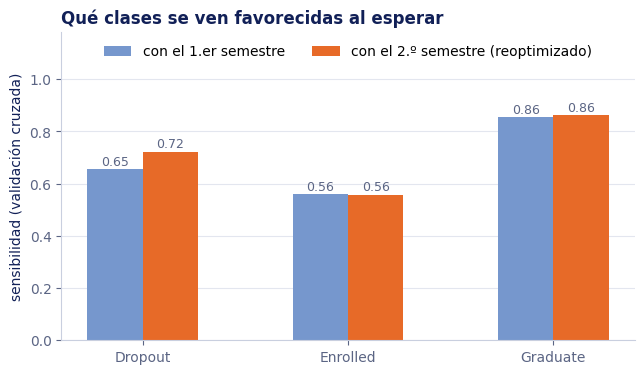

In [27]:
fig, ax = plt.subplots(figsize=(7.4, 4))
x = np.arange(len(CLASES))
w = 0.27
v1 = [estimacion.loc["1.er semestre (30 atributos)", f"sens. {c}"] for c in CLASES]
v2 = [estimacion.loc["+ 2.º semestre, reoptimizado", f"sens. {c}"] for c in CLASES]
ax.bar(x - w / 2, v1, w, color=AZUL, label="con el 1.er semestre")
ax.bar(x + w / 2, v2, w, color=NARANJA, label="con el 2.º semestre (reoptimizado)")
for i in range(len(CLASES)):
    ax.text(x[i] - w / 2, v1[i] + 0.015, f"{v1[i]:.2f}", ha="center", color=GRIS, fontsize=9)
    ax.text(x[i] + w / 2, v2[i] + 0.015, f"{v2[i]:.2f}", ha="center", color=GRIS, fontsize=9)
ax.set_xticks(x)
ax.set_xticklabels(CLASES)
ax.set_ylim(0, 1.18)
ax.set_ylabel("sensibilidad (validación cruzada)")
ax.set_title("Qué clases se ven favorecidas al esperar")
ax.legend(loc="upper center", ncol=2)
ax.grid(axis="x", visible=False)
plt.show()

**Lectura.** Esperar al segundo semestre mejora el F1 macro del SVM de 0.689 a 0.717 con la misma configuración (+0.028; mejora en los 5 pliegues, con una desviación de la diferencia de 0.011) y a 0.713 si se reoptimiza (+0.025). El beneficio se concentra en detectar desertores: su sensibilidad sube de 0.65 a 0.70 con la misma configuración y a 0.72 al reoptimizar, mientras que la de Enrolled casi no cambia (0.56, 0.59 y 0.56) y la de Graduate pasa de 0.86 a 0.87 con la misma configuración y queda en 0.86 al reoptimizar.

La ganancia es real, pero moderada: unos 0.03 de F1 macro. Es probable que parte de ella sea casi trivial, porque los atributos del segundo semestre registran si el estudiante dejó de inscribir o de presentar evaluaciones, es decir, ven el abandono mientras ocurre. Además, esperar cuesta un semestre de intervención, y el apoyo a un estudiante en riesgo es más útil antes de que decida irse.

Por eso **no conviene esperar para decidir**. Conviene actuar con el modelo del primer semestre y, si hay capacidad, reevaluar al cierre del segundo con un segundo modelo que corrija las decisiones. La conclusión depende del costo de intervenir y del beneficio de retener a un estudiante, que aquí no se conocen.

---

## 10. Clasificador final y predicciones sobre el conjunto de prueba

El clasificador final es el de mayor F1 macro de validación cruzada. Se entrena con **todo** el conjunto de entrenamiento, usando solo los 30 atributos del primer semestre (los únicos que existen en el archivo de prueba), y se predicen los 885 estudiantes. El archivo `predicciones.csv` tiene exactamente dos columnas, `id` y `Target`, con los valores `dropout`, `enrolled` o `graduate`.

In [28]:
final = construir_mejor(p_mejor)           # el mejor clasificador, con su mejor configuración
final.fit(X, y)                            # con todo el conjunto de entrenamiento

X_prueba = te[ATRIBUTOS]                   # el orden de columnas coincide con el del entrenamiento
pred = final.predict(X_prueba)

ETIQUETAS = {0: "dropout", 1: "enrolled", 2: "graduate"}      # valores pedidos para la entrega
salida = pd.DataFrame({"id": te["id"].to_numpy(), "Target": [ETIQUETAS[k] for k in pred]})
salida.to_csv(RUTA_SALIDA, index=False)

print("Clasificador final:", mejor_nombre)
print("Archivo generado:", RUTA_SALIDA, "con", salida.shape[0], "filas y las columnas", salida.columns.tolist())
salida.head()

Clasificador final: SVM
Archivo generado: predicciones.csv con 885 filas y las columnas ['id', 'Target']


,id,Target
0,6,graduate
1,12,graduate
2,15,graduate
3,18,enrolled
4,19,graduate


In [29]:
# Comprobaciones del archivo de entrega
leido = pd.read_csv(RUTA_SALIDA)
assert leido.columns.tolist() == ["id", "Target"]
assert len(leido) == 885 == len(te)
assert (leido["id"].to_numpy() == te["id"].to_numpy()).all() and leido["id"].is_unique
assert set(leido["Target"]) <= {"dropout", "enrolled", "graduate"}
assert leido.notna().all().all()
print("El archivo cumple el formato pedido.")

comparar = pd.DataFrame({
    "predicciones en prueba (%)": leido["Target"].value_counts(normalize=True).mul(100).round(1),
    "entrenamiento (%)": tr["Target"].str.lower().value_counts(normalize=True).mul(100).round(1),
}).reindex(["dropout", "enrolled", "graduate"])
print(comparar.to_string())

El archivo cumple el formato pedido.
          predicciones en prueba (%)  entrenamiento (%)
Target                                                 
dropout                         23.7               32.1
enrolled                        22.7               17.9
graduate                        53.6               49.9


**Lectura.** El clasificador final es el SVM con kernel RBF (`C` ≈ 173, `gamma` ≈ 7.8e-4, pesos Enrolled ×2, categorías con menos de 10 estudiantes agrupadas), entrenado con los 3,539 estudiantes y los 30 atributos del primer semestre. El archivo `predicciones.csv` tiene 885 filas y las columnas `id` y `Target`; el notebook comprueba que los `id` coinciden con los del archivo de prueba y que los valores son `dropout`, `enrolled` o `graduate`.

Predice 23.7 % de desertores, 22.7 % de inscritos y 53.6 % de graduados. La mezcla es coherente con la de validación cruzada, donde el mismo modelo predijo 24.8 %, 22.5 % y 52.7 %: el SVM predice menos desertores de los que hay (32 %) porque detecta cerca de dos tercios de ellos. Se espera un F1 macro de prueba cercano a 0.68, que es lo que dieron los pliegues nuevos (0.685), y no al 0.689 de la búsqueda, que es algo optimista.

---

## 11. Discusión y conclusiones

**Desempeño de cada clasificador.**

- **SVM con kernel RBF (F1 macro 0.689).** Fue el mejor porque combina bien muchas señales débiles con una frontera ligeramente curva, y porque los pesos por clase le permiten reforzar a los inscritos. Es el más lento de optimizar (320 s) y el menos interpretable.
- **Regresión logística (0.682).** Quedó a una desviación del SVM, con el menor desvío entre pliegues, y es más rápida e interpretable. Que un modelo lineal casi alcance al RBF indica que la relación entre los atributos del primer semestre y la situación final es, en esencia, casi lineal.
- **Árbol de decisión (0.645).** Es el único que recupera bien a los inscritos (0.63) y da reglas legibles, pero paga con muchas falsas alarmas de Enrolled. Un solo árbol no combina bien muchos atributos débiles.
- **Naive Bayes (0.625).** Es el mejor en sensibilidad de desertores (0.70) y rapidísimo (16 s), pero su supuesto de independencia cuenta varias veces la misma evidencia (las seis variables académicas están muy correlacionadas). Fue la representación categórica, y no el suavizado, lo que lo hizo competitivo.
- **kNN (0.582).** Es el más débil e inestable: sin pesos por clase y con 30 atributos, sus vecinos casi nunca son inscritos (sensibilidad 0.16).

**Lo que enseña el problema.**

1. **Hay un techo cercano a 0.69** con la información del primer semestre. Los errores se concentran en Enrolled y en los desertores con buen desempeño, que son estudiantes que no se distinguen por sus calificaciones.
2. **Los pesos por clase importan.** Reforzar a la clase Enrolled (×2 o `balanced`) aparece en las mejores configuraciones del árbol, el SVM y la regresión logística, justo los tres clasificadores que los admiten, y no en kNN ni Naive Bayes, que no los tienen.
3. **La optimización tiene límites.** Con pliegues nuevos, las mejores configuraciones bajan entre 0.000 y 0.012, así que las diferencias menores a 0.01 entre clasificadores, como la del SVM contra la regresión logística, no son concluyentes.
4. **Para usarlo.** El modelo sirve para ordenar a los estudiantes por riesgo y dirigir el apoyo (acierta el 85 % de lo que marca como desertor), pero no para decisiones individuales definitivas, porque omite a más de una tercera parte de los desertores.

**Limitaciones.** Los datos provienen de una sola institución y de ciclos de 2008 a 2019; los indicadores macroeconómicos varían por cohorte, y pueden actuar como un reloj del ingreso. La búsqueda y la comparación usaron el mismo conjunto de entrenamiento, y el F1 macro de prueba solo lo conocen los profesores.

**Conclusión.** Para predecir al cierre del primer semestre quién se graduará, desertará o seguirá inscrito, el mejor de los cinco clasificadores es el **SVM con kernel RBF**, seguido muy de cerca por la **regresión logística**, que sería la alternativa si se priorizara la simplicidad. Esperar al segundo semestre solo agregaría unos 0.03 de F1 macro, a cambio de perder un semestre de intervención.

---

### Declaración de uso de IA generativa

Este notebook utilizó Claude (Anthropic) como asistente para estructurar el notebook (Markdown), redactar y revisar los textos, así como la depuración de código.

### Referencias

- Realinho, V., Martins, M. V., Machado, J., & Baptista, L. (2021). *Predict Students' Dropout and Academic Success* [Conjunto de datos]. UCI Machine Learning Repository. https://doi.org/10.24432/C5MC89. Licencia CC BY 4.0.
- Realinho, V., Machado, J., Baptista, L., & Martins, M. V. (2022). Predicting student dropout and academic success. *Data, 7*(11), 146. https://doi.org/10.3390/data7110146
- scikit-learn: [Pipeline](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html) · [OneHotEncoder](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html) · [ParameterSampler](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.ParameterSampler.html) · [Métricas](https://scikit-learn.org/stable/modules/model_evaluation.html)